# Learning beta without ground-truth parameters

All estimators receive only **observed acceleration, input u, and instrument z**. No generator coefficients, mixture parameters, latent disturbance draws, true beta, or true measurement-noise calibration are supplied to inference.

- **PF: independent assumption** learns beta and a residual scale under a Gaussian likelihood that ignores correlation between input and disturbance.
- **PF: shared, learned correlation** jointly learns beta, the input response to z, a control-function correlation coefficient, and two residual scales. It models (u,a) conditional on z with a joint Gaussian working likelihood.
- **IV** estimates beta using the observed-data moment sum z*(a-beta*u)=0.

The trajectory generator remains non-Gaussian. The particle models now make explicit Gaussian approximations; they do not know or recover the generator's exact hidden mixture law. Priors are fixed inference choices independent of the generator settings. Posterior intervals are model-based, not guaranteed frequentist coverage under misspecification.

The generation cell simulates acceleration measurements by adding noise to changes in true velocity. This creates observations for the benchmark; true velocities are not passed to any estimator. It is not yet an RFID-based hidden-state experiment. Ground truth is used only for generation and scoring.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
from html import escape
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import HTML, display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "controls" / "scenarios" / "instrumented.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from controls import ParameterParticleFilterEstimator, ParameterPrior, ParameterObservation, InstrumentalVariableEstimator
from controls.scenarios.instruments import generateInstruments
from controls.scenarios.instrumented import generateTrajectory

No event loop hook running.


## Generate observations and retain evaluation truth separately

These settings belong to the simulator. No estimator is constructed here, and no `result.truth` metadata is read. Each observation becomes available at the end of its velocity-change interval.

In [2]:
DURATION, DT = 30.0, 0.1
TRUE_BETA = 0.5  # Generation and scoring only.
INSTRUMENT_SEED, TRAJECTORY_SEED, DISTRIBUTION_SEED = 42, 123, 7
OBSERVATION_SEED = 456
SIMULATED_ACCELERATION_SENSOR_STDDEV = 0.05  # Used to simulate measurements, never supplied to inference.
CASE_DELTAS = {"Shared disturbance": 0.8, "Independent-input control": 0.0}

instruments = generateInstruments(duration=DURATION, dt=DT, seed=INSTRUMENT_SEED)
acceleration_error = np.random.default_rng(OBSERVATION_SEED).normal(
    0, SIMULATED_ACCELERATION_SENSOR_STDDEV, size=(len(instruments), 2)
)
cases = {}
for case_name, delta in CASE_DELTAS.items():
    generated = generateTrajectory(instruments, beta=TRUE_BETA, delta=delta,
                                   seed=TRAJECTORY_SEED, distributionSeed=DISTRIBUTION_SEED)
    velocities = np.array([[s.xdot, s.ydot] for s in generated.scenario.states])
    acceleration_measurements = np.diff(velocities, axis=0) / DT + acceleration_error
    observations = [ParameterObservation(tuple(a), tuple(u), (z.z_x, z.z_y))
                    for a, u, z in zip(acceleration_measurements, generated.inputs, instruments)]
    cases[case_name] = {"observations": observations, "time": np.arange(1, len(observations)+1)*DT}
# Retain only observations in cases, not generator objects or true state arrays.
del generated, velocities
print({name: len(case["observations"]) for name, case in cases.items()})

{'Shared disturbance': 300, 'Independent-input control': 300}


## Inference boundary

The function below accepts only observations, timestep, generic priors, particle count, and a separate inference RNG seed. It cannot receive a trajectory result or generator metadata through its arguments. Changing generator truth while holding observations and inference settings fixed must leave estimates unchanged.

The fixed priors below are not centered on the true beta or initialized using IV. Both particle methods estimate their own residual scales; no true sensor/process-noise scale is supplied.

In [3]:
PARTICLE_COUNT, PARTICLE_SEED = 6000, 789
INFERENCE_PRIOR = ParameterPrior(
    beta=(-3.0, 3.0), inputResponse=(-3.0, 3.0),
    confoundingSlope=(-3.0, 3.0), noiseStddev=(0.01, 10.0),
)

def infer_beta(observations, *, dt, particle_count, seed, prior):
    estimators = {
        "PF: independent assumption": ParameterParticleFilterEstimator(
            mode="independent", particleCount=particle_count, prior=prior, seed=seed),
        "PF: shared, learned correlation": ParameterParticleFilterEstimator(
            mode="shared", particleCount=particle_count, prior=prior, seed=seed),
        "IV": InstrumentalVariableEstimator(),
    }
    estimates = {name: [] for name in estimators}
    for i, observation in enumerate(observations):
        for name, estimator in estimators.items():
            estimate = estimator.update(observation, dt=dt, time=(i+1)*dt)
            estimates[name].append(np.nan if estimate is None else estimate)
    return {"estimators": estimators, "estimates": estimates}

In [4]:
runs = {
    name: infer_beta(case["observations"], dt=DT, particle_count=PARTICLE_COUNT,
                     seed=PARTICLE_SEED, prior=INFERENCE_PRIOR)
    for name, case in cases.items()
}
for name, run in runs.items():
    print(name)
    for label, estimator in run["estimators"].items():
        print(f"  {label}: beta={run['estimates'][label][-1]:.4f}")
        if isinstance(estimator, ParameterParticleFilterEstimator):
            joint_mean = estimator.weights @ estimator.parameterParticles
            print("    Learned working parameters:", dict(zip(estimator.parameterNames, np.round(joint_mean, 4))))

Shared disturbance
  PF: independent assumption: beta=0.6496
    Learned working parameters: {'beta': np.float64(0.6496), 'logResidualStddev': np.float64(-1.4483)}
  PF: shared, learned correlation: beta=0.5133
    Learned working parameters: {'beta': np.float64(0.5133), 'inputResponse': np.float64(1.0491), 'confoundingSlope': np.float64(0.3394), 'logInputStddev': np.float64(-0.1835), 'logResidualStddev': np.float64(-2.441)}
  IV: beta=0.5142
Independent-input control
  PF: independent assumption: beta=0.5170
    Learned working parameters: {'beta': np.float64(0.517), 'logResidualStddev': np.float64(-1.1834)}
  PF: shared, learned correlation: beta=0.5149
    Learned working parameters: {'beta': np.float64(0.5149), 'inputResponse': np.float64(1.0087), 'confoundingSlope': np.float64(0.0573), 'logInputStddev': np.float64(-1.6049), 'logResidualStddev': np.float64(-1.1835)}
  IV: beta=0.5148


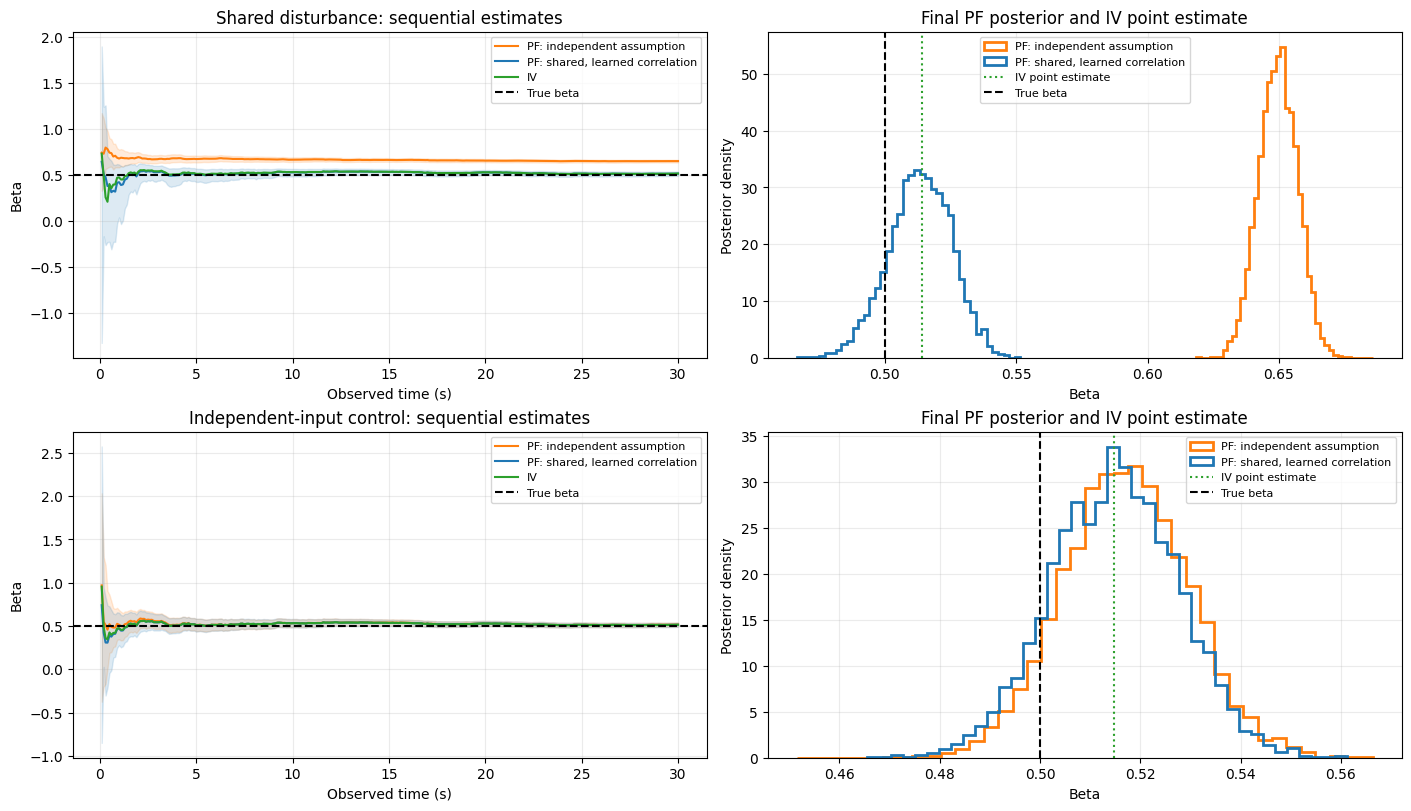

Case,Method,Final beta,Signed error,PF 95% credible interval
Shared disturbance,PF: independent assumption,0.6496,+0.1496,"[0.6352, 0.6638]"
Shared disturbance,"PF: shared, learned correlation",0.5133,+0.0133,"[0.4889, 0.5353]"
Shared disturbance,IV,0.5142,+0.0142,—
Independent-input control,PF: independent assumption,0.5170,+0.0170,"[0.4925, 0.5415]"
Independent-input control,"PF: shared, learned correlation",0.5149,+0.0149,"[0.4899, 0.5389]"
Independent-input control,IV,0.5148,+0.0148,—


In [5]:
colors = {"PF: independent assumption": "tab:orange", "PF: shared, learned correlation": "tab:blue", "IV": "tab:green"}
fig, axes = plt.subplots(len(cases), 2, figsize=(14, 4 * len(cases)), squeeze=False, constrained_layout=True)
rows = []
for row, (case_name, case) in enumerate(cases.items()):
    trace_ax, posterior_ax = axes[row]
    for name, estimator in runs[case_name]["estimators"].items():
        values = np.array(runs[case_name]["estimates"][name])
        trace_ax.plot(case["time"], values, label=name, color=colors[name])
        interval = "—"
        if isinstance(estimator, ParameterParticleFilterEstimator):
            lower = [h.lower95 for h in estimator.history]
            upper = [h.upper95 for h in estimator.history]
            trace_ax.fill_between(case["time"], lower, upper, color=colors[name], alpha=0.15)
            posterior_ax.hist(estimator.particles, weights=estimator.weights, bins=40, density=True,
                              histtype="step", linewidth=2, color=colors[name], label=name)
            interval = f"[{lower[-1]:.4f}, {upper[-1]:.4f}]"
        else:
            if np.isfinite(values[-1]):
                posterior_ax.axvline(values[-1], color=colors[name], linestyle=":", label="IV point estimate")
        rows.append([case_name, name, f"{values[-1]:.4f}", f"{values[-1] - TRUE_BETA:+.4f}", interval])
    trace_ax.axhline(TRUE_BETA, color="black", linestyle="--", label="True beta")
    posterior_ax.axvline(TRUE_BETA, color="black", linestyle="--", label="True beta")
    trace_ax.set(title=f"{case_name}: sequential estimates", xlabel="Observed time (s)", ylabel="Beta")
    posterior_ax.set(title="Final PF posterior and IV point estimate", xlabel="Beta", ylabel="Posterior density")
    for ax in (trace_ax, posterior_ax):
        ax.grid(alpha=0.25)
        ax.legend(fontsize=8)
plt.show()
headers = ["Case", "Method", "Final beta", "Signed error", "PF 95% credible interval"]
html = "<table><thead><tr>" + "".join(f"<th>{escape(h)}</th>" for h in headers) + "</tr></thead><tbody>"
html += "".join("<tr>" + "".join(f"<td>{escape(v)}</td>" for v in row) + "</tr>" for row in rows)
display(HTML(html + "</tbody></table>"))

## Convergence by timestep: instrument-based PF versus IV

Each step adds one observed transition with x/y acceleration, input, and instrument values. Both estimates use the same data prefix at every step. The top-left panel shows the complete history; the top-right magnifies the last 100 steps. The bottom panels show error against evaluation truth and the difference between methods. The shaded band is the PF's model-based 95% credible interval, not an IV confidence interval. Estimates need not improve monotonically, and this single trajectory does not establish asymptotic convergence.

Step 300: PF=0.513293, IV=0.514194, difference=-0.000901


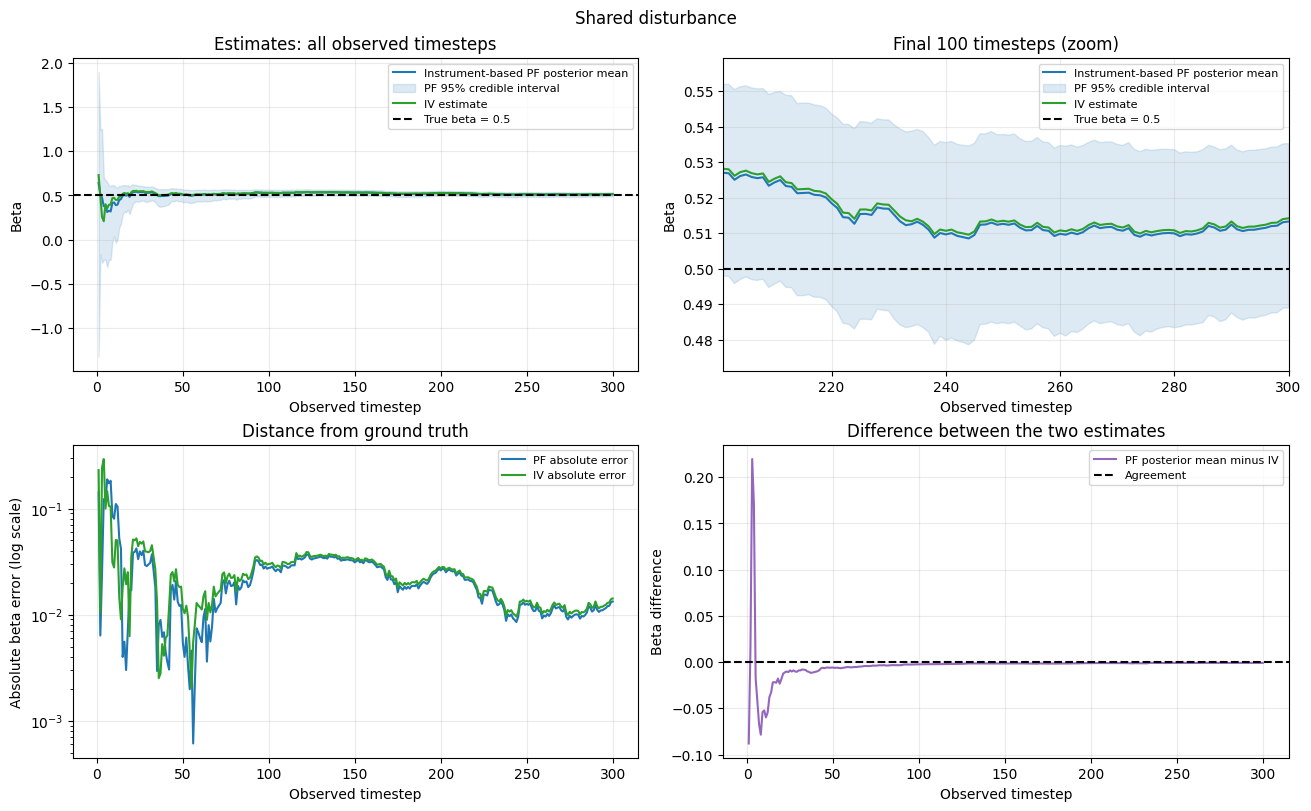

In [6]:
CONVERGENCE_CASE = "Shared disturbance"
case_run = runs[CONVERGENCE_CASE]
pf_name = "PF: shared, learned correlation"
pf_beta = np.array(case_run["estimates"][pf_name])
iv_beta = np.array(case_run["estimates"]["IV"])
steps = np.arange(1, len(pf_beta) + 1)
pf_history = case_run["estimators"][pf_name].history
pf_lower = np.array([h.lower95 for h in pf_history])
pf_upper = np.array([h.upper95 for h in pf_history])

fig, axes = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
for ax in axes[0]:
    ax.plot(steps, pf_beta, color="tab:blue", label="Instrument-based PF posterior mean")
    ax.fill_between(steps, pf_lower, pf_upper, color="tab:blue", alpha=0.15, label="PF 95% credible interval")
    ax.plot(steps, iv_beta, color="tab:green", label="IV estimate")
    ax.axhline(TRUE_BETA, color="black", linestyle="--", label=f"True beta = {TRUE_BETA:g}")
    ax.set(ylabel="Beta")
axes[0, 0].set_title("Estimates: all observed timesteps")
tail_start = max(0, len(steps) - 100)
axes[0, 1].set_xlim(steps[tail_start], steps[-1])
tail_values = np.concatenate((pf_lower[tail_start:], pf_upper[tail_start:], iv_beta[tail_start:], [TRUE_BETA]))
finite_tail = tail_values[np.isfinite(tail_values)]
margin = max(float(np.ptp(finite_tail)) * 0.1, 0.002)
axes[0, 1].set_ylim(finite_tail.min() - margin, finite_tail.max() + margin)
axes[0, 1].set_title(f"Final {len(steps) - tail_start} timesteps (zoom)")

# Log scale exposes smaller errors later; exact zeros are left as gaps.
for values, label, color in ((pf_beta, "PF absolute error", "tab:blue"), (iv_beta, "IV absolute error", "tab:green")):
    error = np.abs(values - TRUE_BETA)
    axes[1, 0].semilogy(steps, np.where(error > 0, error, np.nan), label=label, color=color)
axes[1, 0].set(title="Distance from ground truth", ylabel="Absolute beta error (log scale)")
axes[1, 1].plot(steps, pf_beta - iv_beta, color="tab:purple", label="PF posterior mean minus IV")
axes[1, 1].axhline(0, color="black", linestyle="--", label="Agreement")
axes[1, 1].set(title="Difference between the two estimates", ylabel="Beta difference")
for ax in axes.flat:
    ax.set_xlabel("Observed timestep")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
fig.suptitle(CONVERGENCE_CASE)
# Also retain a standalone copy of this scientific figure.
convergence_image = ROOT / "output" / "beta_convergence.png"
convergence_image.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(convergence_image, dpi=150)
plt.show()
print(f"Step {steps[-1]}: PF={pf_beta[-1]:.6f}, IV={iv_beta[-1]:.6f}, difference={pf_beta[-1]-iv_beta[-1]:+.6f}")

## What the learned shared model means

The model uses a control-function decomposition, with every coefficient and residual scale unknown:

\[
u_t=\alpha z_t+r_t,\qquad
a_t=\beta u_t+\lambda r_t+e_t.
\]

It evaluates the **joint** likelihood p(u,a|z), learning alpha from the input observations as well as learning the outcome relationship. Both r and e have unknown Gaussian working scales. Lambda is a residual association parameter; it is **not** an estimate of the generator's gamma or delta. This parametrization handles shared correlation without pretending those hidden structural coefficients are separately identifiable.

The independent model omits the lambda*r term and the input model. With confounding, it can concentrate confidently around a biased beta. Under non-Gaussian disturbances, the shared Gaussian likelihood remains an approximation; the comparison tests how much modeling residual correlation helps, not recovery of the exact conditional mixture PDF.

Particles remain static parameters. Reweighting, systematic resampling and posterior-invariant Metropolis moves jointly update beta and nuisance parameters. Gaussian sufficient statistics summarize only observations already received, so resampling/moves do not access future observations. See [static-parameter resample/move SMC](https://academic.oup.com/biomet/article-abstract/89/3/539/251804).

Repeat across seeds and instrument strengths before drawing conclusions. The displayed PF credible intervals are model-based; IV is shown as a point estimate without a comparable uncertainty interval. The delta=0 case is a control where the independent assumption is valid, but the two finite-sample particle posteriors need not be identical because they learn different numbers of parameters.